In [5]:
import openpyxl
import pyomo.environ as pe
import numpy as np
import os
import pandas as pd
from datetime import datetime
from datetime import timedelta
import matplotlib.pyplot as plt

# Consumption Data

In [6]:
Year=2019
Month=2
Day=14
N_DEV = 13

# instante inicial e final do dia em análise
day_start_dt = datetime(Year, Month, Day, 0, 0, 0)
day_end_dt = day_start_dt + timedelta(days=1)

# =========================
# DEVICE GROUPS
# =========================
BUFFERED_DEVICES = {0, 2}        # Drinks Refrigerator, Garde Manger
OPERATIONAL_DEVICES = {1, 3, 4, 5, 6}  # Blast Chiller, Ice Machine, Dual Fryer, Salamander, Infrared Shelf
NON_FLEXIBLE_DEVICES = {7, 8, 9}  # Glass Washer, Dish Washer, Convection Oven
POWER_FLEXIBLE_DEVICES = {10, 11, 12}  # Light1, Light2, Exhaust
EXTERNAL_PROFILE_DEVICES = {12}  # Exhaust

POWER_FLEXIBLE_SCHEDULES = {
    10: {
        "name": "Light1",
        "start": 10 * 60,          # 10:00
        "end": 22 * 60 + 30        # 22:30
    },
    11: {
        "name": "Light2",
        "start": 10 * 60,          # 10:00
        "end": 22 * 60 + 30        # 22:30
    }
}
EXTERNAL_PROFILE_DATES = {
    12: "2019-03-11"
}

N_MIN_ACTIVATIONS = 2
T_NO_ACTIVITY_FALLBACK = 5000
T_MIN = 5
T_OFF_FORCED_ON = 5
DAY_MINUTES = 24 * 60
T= DAY_MINUTES

# diretório dos ficheiros
diretorio = '/Users/luismartins/Desktop/Tese/Tese_repository/Data'

# mapeamento appliance -> ficheiro de ativações
activation_files = {
    0: "activations_Drinks_Refrigerator.csv",
    1: "activations_Blast_Chiller.csv",
    2: "activations_Garde_Manger_10.csv",
    3: "activations_Ice_Machine.csv",
    4: "activations_Dual_Fryer.csv",
    5: "activations_Salamander_1.csv",
    6: "activations_Infrared_Shelf.csv",
    7: "activations_Glass_Washer.csv",
    8: "activations_Dish_Washer.csv",
    9: "activations_Convection_Oven_1.csv",
}
external_activation_files = {
    12: "05_Exhaust_activations.xlsx"
}

DEVICE_NAMES = {
    0: "Drinks Refrigerator",
    1: "Blast Chiller",
    2: "Garde Manger",
    3: "Ice Machine",
    4: "Dual Fryer",
    5: "Salamander",
    6: "Infrared Shelf",
    7: "Glass Washer",
    8: "Dish Washer",
    9: "Convection Oven",
    10: "Light 1",
    11: "Light 2",
    12: "Exhaust"
}


In [7]:
# ======================================
# LEITURA DO INFO.XLSX
# ======================================

df_info = pd.read_excel('/Users/luismartins/Desktop/Tese/Tese_repository/Code/RT24 Max Utility/Info_RT24.xlsx')

print("Colunas do Info.xlsx:")
print(df_info.columns.tolist())

# se quiseres confirmar o número de equipamentos do Excel
print("\nNúmero de linhas no Info.xlsx:", len(df_info))

# opcional: garantir consistência
if len(df_info) != N_DEV:
    raise ValueError(f"N_DEV={N_DEV}, mas o Info.xlsx tem {len(df_info)} linhas.")

# parâmetros por equipamento
dev_names = df_info["Dev"].tolist()

# índice do tipo de flexibilidade
Type = df_info["Type"].to_numpy(dtype=int)

# estado inicial
# para já vamos ler do Excel; mais tarde podes forçar a zero ou atualizar dinamicamente
State_Init = df_info["State_Init"].to_numpy(dtype=int)

# potência máxima
Power_max = df_info["Power_max"].to_numpy(dtype=float)

# pesos da componente de potência
Weight_P_max = df_info["Weight_P_max"].to_numpy(dtype=float)
Weight_P_min = df_info["Weight_P_min"].to_numpy(dtype=float)

# percentagens de potência
# MUITO IMPORTANTE: converter de % para fração
Y_max = df_info["Y_max (%)"].to_numpy(dtype=float) / 100.0
Y_min = df_info["Y_min (%)"].to_numpy(dtype=float) / 100.0

# tempo mínimo para manter alteração de potência
TimeHoldPower = df_info["TimeHoldPower"].to_numpy(dtype=float)

# impressão de controlo
print("\nResumo dos equipamentos:")
for j in range(N_DEV):
    print(
        f"{j}: {dev_names[j]} | "
        f"Type={Type[j]} | "
        f"State_Init={State_Init[j]} | "
        f"Pmax={Power_max[j]} | "
        f"Ymin={Y_min[j]} | "
        f"Ymax={Y_max[j]}"
        f" | TimeHoldPower={TimeHoldPower[j]}"
    )

Colunas do Info.xlsx:
['Dev', 'j', 'Type', 'State_Init', 'Power_max', 'Weight_P_max', 'Weight_P_min', 'Y_max (%)', 'Y_min (%)', 'TimeHoldPower']

Número de linhas no Info.xlsx: 13

Resumo dos equipamentos:
0: Drinks Refrigerator | Type=2 | State_Init=0 | Pmax=5000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
1: Blast Chiller | Type=2 | State_Init=0 | Pmax=1500.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
2: Garde Manger | Type=2 | State_Init=0 | Pmax=1000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
3: Ice Machine | Type=2 | State_Init=0 | Pmax=400.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
4: Dual Fryer | Type=2 | State_Init=0 | Pmax=5000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
5: Salamander | Type=2 | State_Init=0 | Pmax=3000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
6: Infrared Shelf | Type=2 | State_Init=0 | Pmax=800.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
7: Glass Washer | Type=0 | State_Init=0 | Pmax=1600.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
8: Dish Washer 

In [8]:
def minute_of_day(ts):
    m = ts.hour * 60 + ts.minute
    if ts.second >= 30:
        m += 1
    return min(m, 1439)

def load_activation_day_csv(diretorio, nome_do_arquivo, target_date):
    caminho_arquivo = os.path.join(diretorio, nome_do_arquivo)
    if not os.path.exists(caminho_arquivo):
        raise FileNotFoundError(f"File not found: {caminho_arquivo}")

    df = pd.read_csv(caminho_arquivo, sep=';').iloc[:, 0:3].copy()

    df["first_min_on"] = pd.to_datetime(df["first_min_on"], utc=True, errors="coerce")
    df["last_min_on"]  = pd.to_datetime(df["last_min_on"],  utc=True, errors="coerce")

    df["first_min_on"] = df["first_min_on"].dt.tz_convert(None)
    df["last_min_on"]  = df["last_min_on"].dt.tz_convert(None)

    df = df.dropna(subset=["first_min_on", "last_min_on"]).sort_values("first_min_on").reset_index(drop=True)

    target_date = pd.to_datetime(target_date).date()
    df_day = df[df["first_min_on"].dt.date == target_date].copy().reset_index(drop=True)

    return df_day
def build_X_day_for_device(j, nome_do_arquivo, diretorio, target_date, X_day):
    """
    Constrói X_day[:, j] para o dia inteiro.
    """
    X_day[:, j] = 0

    df_day = load_activation_day_csv(diretorio, nome_do_arquivo, target_date)

    if df_day.empty:
        return

    for _, row in df_day.iterrows():
        start = minute_of_day(row["first_min_on"])
        end   = minute_of_day(row["last_min_on"])

        if end >= start:
            X_day[start:end + 1, j] = 1
        else:
            X_day[start:1440, j] = 1
            X_day[0:end + 1, j] = 1

In [9]:
# 1) Construir X_day global apenas para devices com ficheiro
X_day = np.zeros((T, N_DEV), dtype=int)

for j, nome_do_arquivo in activation_files.items():
    build_X_day_for_device(
        j=j,
        nome_do_arquivo=nome_do_arquivo,
        diretorio=diretorio,
        target_date=day_start_dt.date(),
        X_day=X_day
    )

# 2) Inicializar matrizes
X_onoff_FC_matrix = np.zeros((T, N_DEV), dtype=int)

target_date = day_start_dt.date()

# 3) Preencher baseline com ativações reais
X_onoff_FC_matrix[:, :] = X_day[:T, :]

print("\nX_onoff_FC_matrix (baseline) for the day:")
print(X_onoff_FC_matrix)


X_onoff_FC_matrix (baseline) for the day:
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


# Caracterização W devices (T_ON/T_OFF) - Paper

In [10]:
def get_time_zone(minute):
    """
    0 -> 00:00 - 09:59
    1 -> 10:00 - 19:29
    2 -> 19:30 - 22:29
    3 -> 22:30 - 23:59
    """
    if 0 <= minute <= 599:
        return 0
    elif 600 <= minute <= 1169:
        return 1
    elif 1170 <= minute <= 1349:
        return 2
    else:
        return 3


def compute_operational_ton_toff_day(j, nome_do_arquivo, diretorio, target_date):
    """
    Operational devices:
    T_ON/T_OFF por timezone, avaliando presença ON dentro da timezone,
    mesmo quando a ativação começou antes da timezone.

    Regras:
      - se não há minutos ON na timezone:
            T_ON  = T_NO_ACTIVITY_FALLBACK
            T_OFF = T_NO_ACTIVITY_FALLBACK

      - se há minutos ON na timezone:
            T_ON = duração total ON dentro da timezone, ou mediana dos blocos ON na timezone

            se houver gaps OFF observados:
                T_OFF = mediana dos gaps OFF
            senão:
                T_OFF = T_OFF_FORCED_ON
    """

    T_ON_day_j = np.full(DAY_MINUTES, T_NO_ACTIVITY_FALLBACK, dtype=int)
    T_OFF_day_j = np.full(DAY_MINUTES, T_NO_ACTIVITY_FALLBACK, dtype=int)

    df_day = load_activation_day_csv(diretorio, nome_do_arquivo, target_date)

    if df_day.empty:
        return T_ON_day_j, T_OFF_day_j

    # construir X_day do device
    X_dev = np.zeros(DAY_MINUTES, dtype=int)

    for _, row in df_day.iterrows():
        start = minute_of_day(row["first_min_on"])
        end = minute_of_day(row["last_min_on"])

        if end >= start:
            X_dev[start:end + 1] = 1
        else:
            X_dev[start:DAY_MINUTES] = 1
            X_dev[0:end + 1] = 1

    zone_limits = {
        0: (0, 600),       # 00:00 - 09:59
        1: (600, 1170),   # 10:00 - 19:29
        2: (1170, 1350),  # 19:30 - 22:29
        3: (1350, 1440),  # 22:30 - 23:59
    }

    zone_ton = {}
    zone_toff = {}

    for z, (start_z, end_z) in zone_limits.items():
        X_zone = X_dev[start_z:end_z]

        on_minutes = int(np.sum(X_zone))

        # sem presença ON na timezone
        if on_minutes == 0:
            zone_ton[z] = T_NO_ACTIVITY_FALLBACK
            zone_toff[z] = T_NO_ACTIVITY_FALLBACK
            continue

        # há presença ON na timezone
        # calcular blocos ON e OFF dentro da timezone
        on_blocks = []
        off_blocks = []

        current_state = X_zone[0]
        count = 1

        for val in X_zone[1:]:
            if val == current_state:
                count += 1
            else:
                if current_state == 1:
                    on_blocks.append(count)
                else:
                    off_blocks.append(count)

                current_state = val
                count = 1

        # fechar último bloco
        if current_state == 1:
            on_blocks.append(count)
        else:
            off_blocks.append(count)

        # T_ON: se há blocos ON, usa mediana dos blocos ON
        if len(on_blocks) > 0:
            ton_z = max(1, int(np.median(on_blocks)))
        else:
            ton_z = T_NO_ACTIVITY_FALLBACK

        # T_OFF:
        # só usar gaps OFF se existirem dentro da zona
        # se está sempre ON ou sem OFF observado, usar forced-on
        valid_off_blocks = [b for b in off_blocks if b > 0]

        if len(valid_off_blocks) > 0:
            toff_z = max(1, int(np.median(valid_off_blocks)))
        else:
            toff_z = T_OFF_FORCED_ON

        zone_ton[z] = ton_z
        zone_toff[z] = toff_z

    for t in range(DAY_MINUTES):
        z = get_time_zone(t)
        T_ON_day_j[t] = zone_ton[z]
        T_OFF_day_j[t] = zone_toff[z]
        
    return T_ON_day_j, T_OFF_day_j

def compute_buffered_ton_toff_for_window(j, X_window):
    """
    Buffered devices:
    Replica a lógica da Ana dentro da janela de 60 min.
    """
    T_ON_window_j = np.zeros(T, dtype=int)
    T_OFF_window_j = np.zeros(T, dtype=int)

    cont_on = 0
    cont_off = 0
    periodo = 0
    first = 0

    for i in range(T):
        if i == 0 and X_window[i] == 0:
            first = 0

        if X_window[i] == 0:
            cont_off += 1

        if X_window[i] == 1:
            cont_on += 1

        if X_window[i] == 1 and i < T - 1 and X_window[i + 1] == 0:
            periodo = i
            for k in range(first, periodo + 1):
                T_OFF_window_j[k] = max(1, cont_off)
                T_ON_window_j[k] = max(1, cont_on)

            cont_on = 1
            cont_off = 1
            first = periodo + 1

        elif X_window[i] == 1 and i == T - 1:
            for k in range(first, T):
                T_OFF_window_j[k] = max(1, cont_off)
                T_ON_window_j[k] = max(1, cont_on)

        else:
            if i == T - 1:
                for k in range(first, T):
                    if X_window[i] == 1:
                        T_ON_window_j[k] = max(1, cont_on)
                        T_OFF_window_j[k] = max(1, T_ON_window_j[k])
                    else:
                        T_OFF_window_j[k] = max(1, cont_off - 1)
                        T_ON_window_j[k] = max(1, T_OFF_window_j[k])

    T_ON_window_j[T_ON_window_j <= 0] = 1
    T_OFF_window_j[T_OFF_window_j <= 0] = 1

    return T_ON_window_j, T_OFF_window_j

def build_X_day_all_devices(day_start_dt, activation_files, diretorio):
    X_day = np.zeros((DAY_MINUTES, N_DEV), dtype=int)
    target_date = day_start_dt.date()

    for j in range(N_DEV):
        build_X_day_for_device(
            j=j,
            nome_do_arquivo=activation_files[j],
            diretorio=diretorio,
            target_date=target_date,
            X_day=X_day
        )

    return X_day

def build_power_flexible_schedule(T, start_minute, end_minute):
    x = np.zeros(T, dtype=int)

    if end_minute > start_minute:
        x[start_minute:end_minute] = 1
    else:
        # caso atravesse meia-noite
        x[start_minute:T] = 1
        x[0:end_minute] = 1

    return x


def get_power_flexible_ton_toff(T, start_minute, end_minute):
    if end_minute > start_minute:
        on_duration = end_minute - start_minute
    else:
        on_duration = (T - start_minute) + end_minute

    off_duration = T - on_duration

    T_ON_j = np.full(T, max(on_duration, 1), dtype=int)
    T_OFF_j = np.full(T, max(off_duration, 1), dtype=int)

    return T_ON_j, T_OFF_j

def build_external_profile_from_activation_file(
    diretorio,
    nome_do_arquivo,
    target_date,
    T=1440
):

    caminho_arquivo = os.path.join(diretorio, nome_do_arquivo)

    if not os.path.exists(caminho_arquivo):
        raise FileNotFoundError(f"File not found: {caminho_arquivo}")

    df = pd.read_excel(caminho_arquivo).iloc[:, 0:3].copy()

    df.columns = df.columns.str.strip()

    df["First_min_on"] = pd.to_datetime(
        df["First_min_on"],
        utc=True,
        errors="coerce"
    )

    df["Last_min_on"] = pd.to_datetime(
        df["Last_min_on"],
        utc=True,
        errors="coerce"
    )

    df["First_min_on"] = df["First_min_on"].dt.tz_convert(None)
    df["Last_min_on"] = df["Last_min_on"].dt.tz_convert(None)

    # IMPORTANTÍSSIMO
    target_date = pd.to_datetime(target_date).date()

    df = df[
        df["First_min_on"].dt.date == target_date
    ].copy()

    x = np.zeros(T, dtype=int)

    for _, row in df.iterrows():

        start = minute_of_day(row["First_min_on"])
        end = minute_of_day(row["Last_min_on"])

        if end >= start:
            x[start:end + 1] = 1
        else:
            x[start:T] = 1
            x[0:end + 1] = 1

    return x

In [11]:
# =========================
# BUILD X_ONOFF_FC_MATRIX
# =========================
T_ON_FC_matrix = np.ones((T, N_DEV), dtype=int)
T_OFF_FC_matrix = np.ones((T, N_DEV), dtype=int)

# 1) Adicionar devices power-flexible simulados
for j in POWER_FLEXIBLE_DEVICES:

    # só os que têm horário definido manualmente
    if j not in POWER_FLEXIBLE_SCHEDULES:
        continue

    sched = POWER_FLEXIBLE_SCHEDULES[j]

    X_onoff_FC_matrix[:, j] = build_power_flexible_schedule(
        T=T,
        start_minute=sched["start"],
        end_minute=sched["end"]
    )
# 2) Adicionar perfis externos
for j in EXTERNAL_PROFILE_DEVICES:

    X_onoff_FC_matrix[:, j] = build_external_profile_from_activation_file(
        diretorio=diretorio,
        nome_do_arquivo=external_activation_files[j],
        target_date=EXTERNAL_PROFILE_DATES[j],
        T=T
    )
    
# =========================
# BUILD Y_FC_MATRIX
# =========================

Y_FC_matrix = np.zeros((T, N_DEV), dtype=float)

for j in range(N_DEV):

    if Type[j] == 1:  # power-flexible
        Y_FC_matrix[:, j] = X_onoff_FC_matrix[:, j] * Y_max[j]

    else:
        # Para devices não power-flexible, Y não é relevante.
        # Mas pode ficar igual a X para manter consistência.
        Y_FC_matrix[:, j] = X_onoff_FC_matrix[:, j]
        

# 5) Construir T_ON / T_OFF
for j in range(N_DEV):
    
    if j in POWER_FLEXIBLE_DEVICES:

        if j in POWER_FLEXIBLE_SCHEDULES:

            sched = POWER_FLEXIBLE_SCHEDULES[j]
            T_ON_j, T_OFF_j = get_power_flexible_ton_toff(
                T=T,
                start_minute=sched["start"],
                end_minute=sched["end"]
            )
        elif j in EXTERNAL_PROFILE_DEVICES:
            on_minutes = int(np.sum(X_onoff_FC_matrix[:, j]))
            off_minutes = T - on_minutes
            T_ON_j = np.full(T, max(on_minutes, 1), dtype=int)
            T_OFF_j = np.full(T, max(off_minutes, 1), dtype=int)
        else:
            T_ON_j = np.ones(T, dtype=int)
            T_OFF_j = np.ones(T, dtype=int)

    elif j in BUFFERED_DEVICES:
        T_ON_j, T_OFF_j = compute_buffered_ton_toff_for_window(
            j,
            X_onoff_FC_matrix[:, j]
        )

    elif j in OPERATIONAL_DEVICES:
        nome_do_arquivo = activation_files[j]

        T_ON_j, T_OFF_j = compute_operational_ton_toff_day(
            j=j,
            nome_do_arquivo=nome_do_arquivo,
            diretorio=diretorio,
            target_date=target_date
        )

    else:
        T_ON_j = np.ones(T, dtype=int)
        T_OFF_j = np.ones(T, dtype=int)

    T_ON_FC_matrix[:, j] = T_ON_j
    T_OFF_FC_matrix[:, j] = T_OFF_j

In [12]:
def compute_time_weight(X, T_ON, T_OFF):
    """
    Computes W(t) according to the paper.

    Parameters
    ----------
    X : ndarray (1440,)
        Binary appliance state.

    T_ON : ndarray (1440,)
    T_OFF : ndarray (1440,)

    Returns
    -------
    W : ndarray (1440,)
    """

    T = len(X)

    W = np.zeros(T)

    # ---------- Initialization ----------

    if X[0] == 0:
        W[0] = 1 + 9 / T_OFF[0]
    else:
        W[0] = 10 - 9 / T_ON[0]

    # ---------- Evolution ----------

    for t in range(1, T):

        if X[t] == 0:

            W[t] = W[t-1] + 9 / T_OFF[t]

        else:

            W[t] = W[t-1] - 9 / T_ON[t]

        W[t] = np.clip(W[t], 1, 10)

    return W

def compute_power_weight(Y, Y_min, Y_max, W_P_min, W_P_max, m=1e-6):
    Y_safe = np.clip(Y, Y_min, Y_max)

    WP = W_P_min + ((W_P_max - W_P_min) * (Y_safe - Y_min)) / (
        (Y_max - Y_min) + m
    )

    return np.clip(WP, min(W_P_min, W_P_max), max(W_P_min, W_P_max))

WT_FC_matrix = np.zeros((T, N_DEV))
WP_FC_matrix = np.zeros((T, N_DEV))

for j in range(N_DEV):

    if Type[j] == 2:  # time-flexible
        WT_FC_matrix[:, j] = compute_time_weight(
            X_onoff_FC_matrix[:, j],
            T_ON_FC_matrix[:, j],
            T_OFF_FC_matrix[:, j]
        )

    elif Type[j] == 1:  # power-flexible
        WP_j = compute_power_weight(
            Y_FC_matrix[:, j],
            Y_min[j],
            Y_max[j],
            Weight_P_min[j],
            Weight_P_max[j]
        )
        WP_FC_matrix[:, j] = np.where(
            X_onoff_FC_matrix[:, j] == 1,
            WP_j,
            np.nan
        )

In [13]:
def compute_weight_metrics(W_matrix, Type, dev_names, tol=1e-6):

    rows = []

    for j in np.where(Type == 2)[0]:

        W = W_matrix[:, j]
        W = W[~np.isnan(W)]

        at_min = np.isclose(W, 1.0, atol=tol)
        at_max = np.isclose(W, 10.0, atol=tol)

        inside = ~(at_min | at_max)

        rows.append({

            "Device": dev_names[j],

            "WT = 1 [min]": int(at_min.sum()),
            "WT = 10 [min]": int(at_max.sum()),

            "1 < WT < 10 [min]": int(inside.sum()),

            "WT = 1 [%]": 100*at_min.mean(),
            "WT = 10 [%]": 100*at_max.mean(),

            "1 < WT < 10 [%]": 100*inside.mean(),

            "Average WT": W.mean(),
            "Std WT": W.std()

        })

    return pd.DataFrame(rows)

metrics_original = compute_weight_metrics(
    WT_FC_matrix,
    Type,
    dev_names
)
display(metrics_original)

,Device,WT = 1 [min],WT = 10 [min],1 < WT < 10 [min],WT = 1 [%],WT = 10 [%],1 < WT < 10 [%],Average WT,Std WT
0,Drinks Refrigerator,1,30,1409,0.069444,2.083333,97.847222,5.711028,2.552906
1,Blast Chiller,526,85,829,36.527778,5.902778,57.569444,2.448778,2.604674
2,Garde Manger,1,191,1248,0.069444,13.263889,86.666667,6.668497,2.381586
3,Ice Machine,935,178,327,64.930556,12.361111,22.708333,3.107813,3.272950
4,Dual Fryer,129,198,1113,8.958333,13.750000,77.291667,4.029429,3.244265
5,Salamander,174,119,1147,12.083333,8.263889,79.652778,3.753079,3.164094
6,Infrared Shelf,268,121,1051,18.611111,8.402778,72.986111,3.324662,3.068783


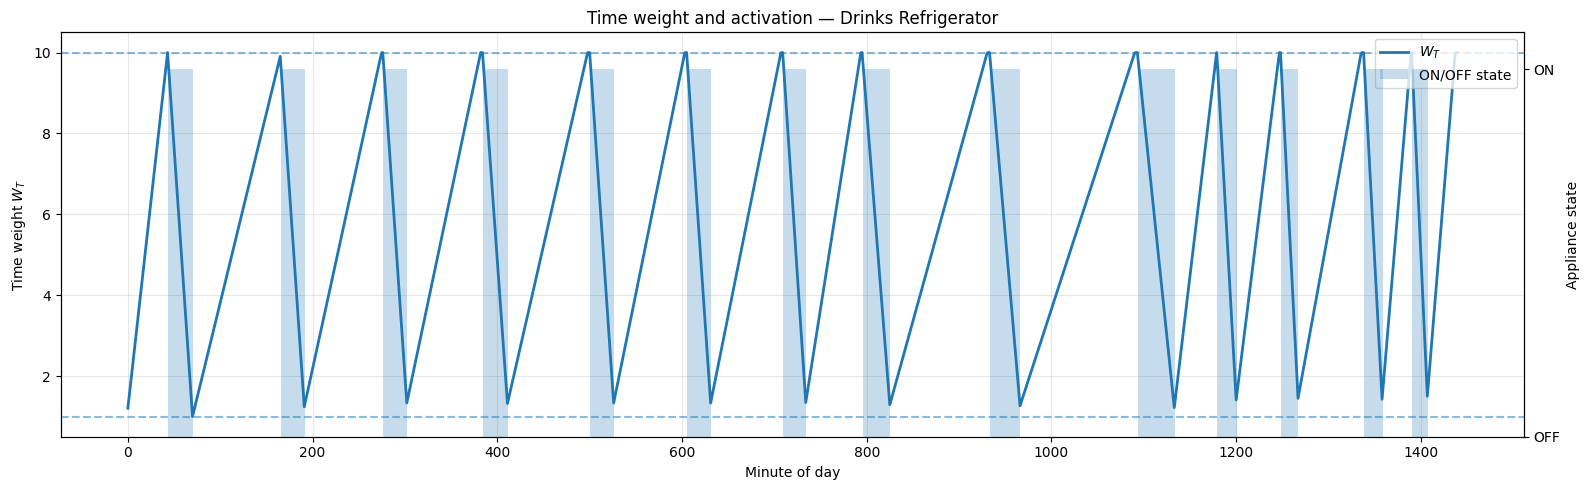

In [14]:
def plot_device_weight_and_activation(
    device,
    W_matrix,
    X_matrix,
    dev_names,
    Type=None,
    figsize=(16, 5)
):
    """
    Plots the time-weight trajectory and ON/OFF activation
    of a single device.

    Parameters
    ----------
    device : str or int
        Device name or index.

    W_matrix : ndarray, shape (T, N_DEV)
        Matrix containing time weights.

    X_matrix : ndarray, shape (T, N_DEV)
        Binary ON/OFF state matrix.

    dev_names : list
        Device names.

    Type : array-like, optional
        Device type vector.

    figsize : tuple
        Figure size.
    """

    # Select device
    if isinstance(device, str):

        exact_matches = [
            j for j, name in enumerate(dev_names)
            if name.lower() == device.lower()
        ]

        if exact_matches:
            j = exact_matches[0]

        else:
            partial_matches = [
                j for j, name in enumerate(dev_names)
                if device.lower() in name.lower()
            ]

            if len(partial_matches) == 0:
                raise ValueError(
                    f"Device '{device}' not found."
                )

            if len(partial_matches) > 1:
                matching_names = [
                    dev_names[j] for j in partial_matches
                ]

                raise ValueError(
                    f"Several devices match '{device}': "
                    f"{matching_names}"
                )

            j = partial_matches[0]

    elif isinstance(device, (int, np.integer)):

        j = int(device)

        if j < 0 or j >= len(dev_names):
            raise IndexError(
                f"Device index must be between 0 and "
                f"{len(dev_names) - 1}."
            )

    else:
        raise TypeError(
            "'device' must be a device name or integer index."
        )

    if Type is not None and Type[j] != 2:
        raise ValueError(
            f"{dev_names[j]} is not time-flexible "
            f"(Type = {Type[j]})."
        )

    time = np.arange(W_matrix.shape[0])

    fig, ax_weight = plt.subplots(figsize=figsize)

    # Weight axis
    weight_line, = ax_weight.plot(
        time,
        W_matrix[:, j],
        lw=2,
        label=r"$W_T$"
    )

    ax_weight.axhline(
        1,
        linestyle="--",
        alpha=0.5
    )

    ax_weight.axhline(
        10,
        linestyle="--",
        alpha=0.5
    )

    ax_weight.set_ylim(0.5, 10.5)
    ax_weight.set_xlabel("Minute of day")
    ax_weight.set_ylabel(r"Time weight $W_T$")
    ax_weight.grid(alpha=0.3)

    # Activation axis
    ax_state = ax_weight.twinx()

    activation_bars = ax_state.bar(
        time,
        X_matrix[:, j],
        width=1.0,
        alpha=0.25,
        label="ON/OFF state"
    )

    ax_state.set_ylim(0, 1.1)
    ax_state.set_yticks([0, 1])
    ax_state.set_yticklabels(["OFF", "ON"])
    ax_state.set_ylabel("Appliance state")

    ax_weight.set_title(
        f"Time weight and activation — {dev_names[j]}"
    )

    # Combined legend
    handles_1, labels_1 = ax_weight.get_legend_handles_labels()
    handles_2, labels_2 = ax_state.get_legend_handles_labels()

    ax_weight.legend(
        handles_1 + handles_2,
        labels_1 + labels_2,
        loc="upper right"
    )

    plt.tight_layout()
    plt.show()
plot_device_weight_and_activation(
    device="Drinks Refrigerator",
    W_matrix=WT_FC_matrix,
    X_matrix=X_onoff_FC_matrix,
    dev_names=dev_names,
    Type=Type
)

# Caracterização baseada nas transições

In [15]:
def compute_transition_based_weight(X):
    """
    Computes time-flexibility weights directly from the forecasted
    ON/OFF episodes.

    For an OFF episode:
        weight increases linearly from 1 to 10.

    For an ON episode:
        weight decreases linearly from 10 to 1.

    Parameters
    ----------
    X : array-like, shape (T,)
        Forecasted binary appliance state.

    Returns
    -------
    W : ndarray, shape (T,)
        Transition-based weight trajectory.
    """

    X = np.asarray(X, dtype=int)
    T = len(X)

    W = np.zeros(T, dtype=float)

    i = 0

    while i < T:

        state = X[i]

        # Find the end of the current constant-state episode
        end = i

        while end + 1 < T and X[end + 1] == state:
            end += 1

        episode_length = end - i + 1

        # Normalized position in the episode
        if episode_length == 1:
            progress = np.array([1.0])
        else:
            progress = np.linspace(
                0.0,
                1.0,
                episode_length
            )

        if state == 0:
            # OFF: urgency to switch ON increases
            W[i:end + 1] = 1.0 + 9.0 * progress

        else:
            # ON: urgency to remain ON decreases
            W[i:end + 1] = 10.0 - 9.0 * progress

        i = end + 1

    return W

In [16]:
WT_transition_matrix = np.full(
    (T, N_DEV),
    np.nan,
    dtype=float
)

for j in range(N_DEV):

    if Type[j] == 2:

        WT_transition_matrix[:, j] = (
            compute_transition_based_weight(
                X_onoff_FC_matrix[:, j]
            )
        )

In [17]:
def compute_weight_boundary_metrics(
    W_matrix,
    Type,
    dev_names,
    tol=1e-6
):
    rows = []

    for j in np.where(Type == 2)[0]:

        W_j = W_matrix[:, j]

        valid = ~np.isnan(W_j)
        W_valid = W_j[valid]

        rows.append({
            "Device": dev_names[j],
            "WT = 10 [min]": int(
                np.sum(
                    np.isclose(
                        W_valid,
                        10.0,
                        atol=tol
                    )
                )
            ),
            "WT = 1 [min]": int(
                np.sum(
                    np.isclose(
                        W_valid,
                        1.0,
                        atol=tol
                    )
                )
            ),
            "WT = 10 [%]": (
                100
                * np.mean(
                    np.isclose(
                        W_valid,
                        10.0,
                        atol=tol
                    )
                )
            ),
            "WT = 1 [%]": (
                100
                * np.mean(
                    np.isclose(
                        W_valid,
                        1.0,
                        atol=tol
                    )
                )
            )
        })

    return pd.DataFrame(rows)

In [18]:
metrics_original = compute_weight_boundary_metrics(
    WT_FC_matrix,
    Type,
    dev_names
)

metrics_transition = compute_weight_boundary_metrics(
    WT_transition_matrix,
    Type,
    dev_names
)

display(metrics_original)
display(metrics_transition)

,Device,WT = 10 [min],WT = 1 [min],WT = 10 [%],WT = 1 [%]
0,Drinks Refrigerator,30,1,2.083333,0.069444
1,Blast Chiller,85,526,5.902778,36.527778
2,Garde Manger,191,1,13.263889,0.069444
3,Ice Machine,178,935,12.361111,64.930556
4,Dual Fryer,198,129,13.750000,8.958333
5,Salamander,119,174,8.263889,12.083333
6,Infrared Shelf,121,268,8.402778,18.611111


,Device,WT = 10 [min],WT = 1 [min],WT = 10 [%],WT = 1 [%]
0,Drinks Refrigerator,29,29,2.013889,2.013889
1,Blast Chiller,21,21,1.458333,1.458333
2,Garde Manger,97,97,6.736111,6.736111
3,Ice Machine,151,146,10.486111,10.138889
4,Dual Fryer,149,148,10.347222,10.277778
5,Salamander,3,3,0.208333,0.208333
6,Infrared Shelf,9,9,0.625000,0.625000


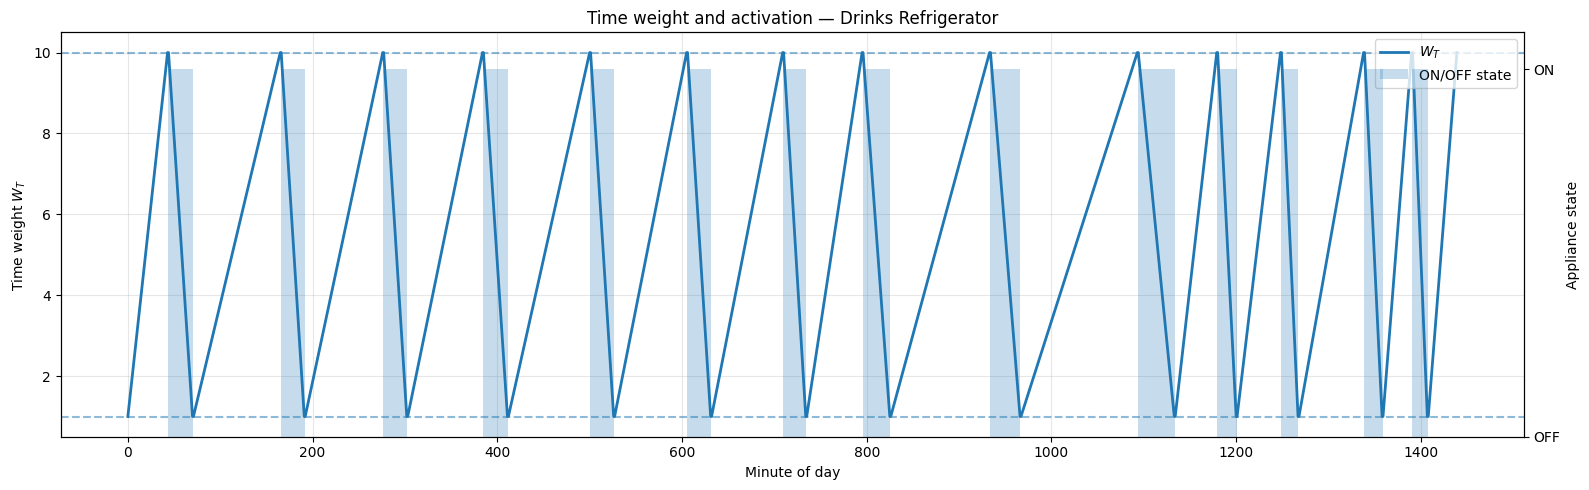

In [19]:
def plot_device_weight_and_activation(
    device,
    W_matrix,
    X_matrix,
    dev_names,
    Type=None,
    figsize=(16, 5)
):
    """
    Plots the time-weight trajectory and ON/OFF activation
    of a single device.

    Parameters
    ----------
    device : str or int
        Device name or index.

    W_matrix : ndarray, shape (T, N_DEV)
        Matrix containing time weights.

    X_matrix : ndarray, shape (T, N_DEV)
        Binary ON/OFF state matrix.

    dev_names : list
        Device names.

    Type : array-like, optional
        Device type vector.

    figsize : tuple
        Figure size.
    """

    # Select device
    if isinstance(device, str):

        exact_matches = [
            j for j, name in enumerate(dev_names)
            if name.lower() == device.lower()
        ]

        if exact_matches:
            j = exact_matches[0]

        else:
            partial_matches = [
                j for j, name in enumerate(dev_names)
                if device.lower() in name.lower()
            ]

            if len(partial_matches) == 0:
                raise ValueError(
                    f"Device '{device}' not found."
                )

            if len(partial_matches) > 1:
                matching_names = [
                    dev_names[j] for j in partial_matches
                ]

                raise ValueError(
                    f"Several devices match '{device}': "
                    f"{matching_names}"
                )

            j = partial_matches[0]

    elif isinstance(device, (int, np.integer)):

        j = int(device)

        if j < 0 or j >= len(dev_names):
            raise IndexError(
                f"Device index must be between 0 and "
                f"{len(dev_names) - 1}."
            )

    else:
        raise TypeError(
            "'device' must be a device name or integer index."
        )

    if Type is not None and Type[j] != 2:
        raise ValueError(
            f"{dev_names[j]} is not time-flexible "
            f"(Type = {Type[j]})."
        )

    time = np.arange(W_matrix.shape[0])

    fig, ax_weight = plt.subplots(figsize=figsize)

    # Weight axis
    weight_line, = ax_weight.plot(
        time,
        W_matrix[:, j],
        lw=2,
        label=r"$W_T$"
    )

    ax_weight.axhline(
        1,
        linestyle="--",
        alpha=0.5
    )

    ax_weight.axhline(
        10,
        linestyle="--",
        alpha=0.5
    )

    ax_weight.set_ylim(0.5, 10.5)
    ax_weight.set_xlabel("Minute of day")
    ax_weight.set_ylabel(r"Time weight $W_T$")
    ax_weight.grid(alpha=0.3)

    # Activation axis
    ax_state = ax_weight.twinx()

    activation_bars = ax_state.bar(
        time,
        X_matrix[:, j],
        width=1.0,
        alpha=0.25,
        label="ON/OFF state"
    )

    ax_state.set_ylim(0, 1.1)
    ax_state.set_yticks([0, 1])
    ax_state.set_yticklabels(["OFF", "ON"])
    ax_state.set_ylabel("Appliance state")

    ax_weight.set_title(
        f"Time weight and activation — {dev_names[j]}"
    )

    # Combined legend
    handles_1, labels_1 = ax_weight.get_legend_handles_labels()
    handles_2, labels_2 = ax_state.get_legend_handles_labels()

    ax_weight.legend(
        handles_1 + handles_2,
        labels_1 + labels_2,
        loc="upper right"
    )

    plt.tight_layout()
    plt.show()
plot_device_weight_and_activation(
    device="Drinks Refrigerator",
    W_matrix=WT_transition_matrix,
    X_matrix=X_onoff_FC_matrix,
    dev_names=dev_names,
    Type=Type
)

In [20]:
metrics_transition = compute_weight_metrics(
    WT_transition_matrix,
    Type,
    dev_names
)
display(metrics_transition)

,Device,WT = 1 [min],WT = 10 [min],1 < WT < 10 [min],WT = 1 [%],WT = 10 [%],1 < WT < 10 [%],Average WT,Std WT
0,Drinks Refrigerator,29,29,1382,2.013889,2.013889,95.972222,5.500000,2.651371
1,Blast Chiller,21,21,1398,1.458333,1.458333,97.083333,5.500000,2.642823
2,Garde Manger,97,97,1246,6.736111,6.736111,86.527778,5.500000,2.792667
3,Ice Machine,146,151,1143,10.138889,10.486111,79.375000,5.515625,2.969308
4,Dual Fryer,148,149,1143,10.277778,10.347222,79.375000,5.503125,2.965839
5,Salamander,3,3,1434,0.208333,0.208333,99.583333,5.500000,2.603508
6,Infrared Shelf,9,9,1422,0.625000,0.625000,98.750000,5.500000,2.615408


# Plots Finais

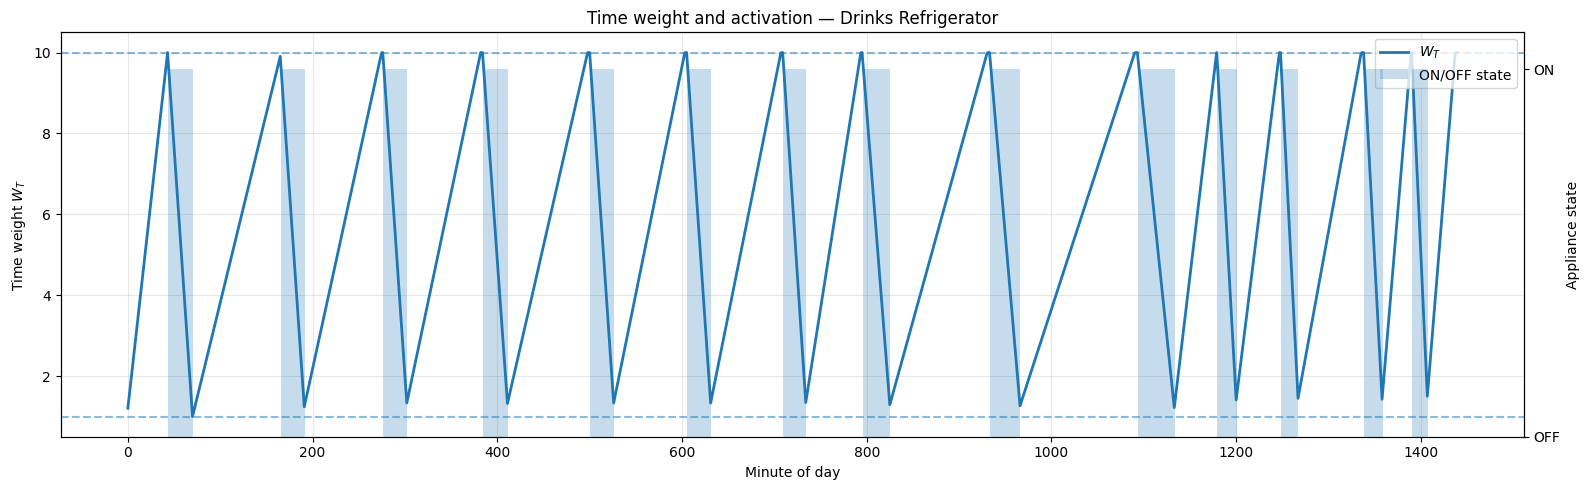

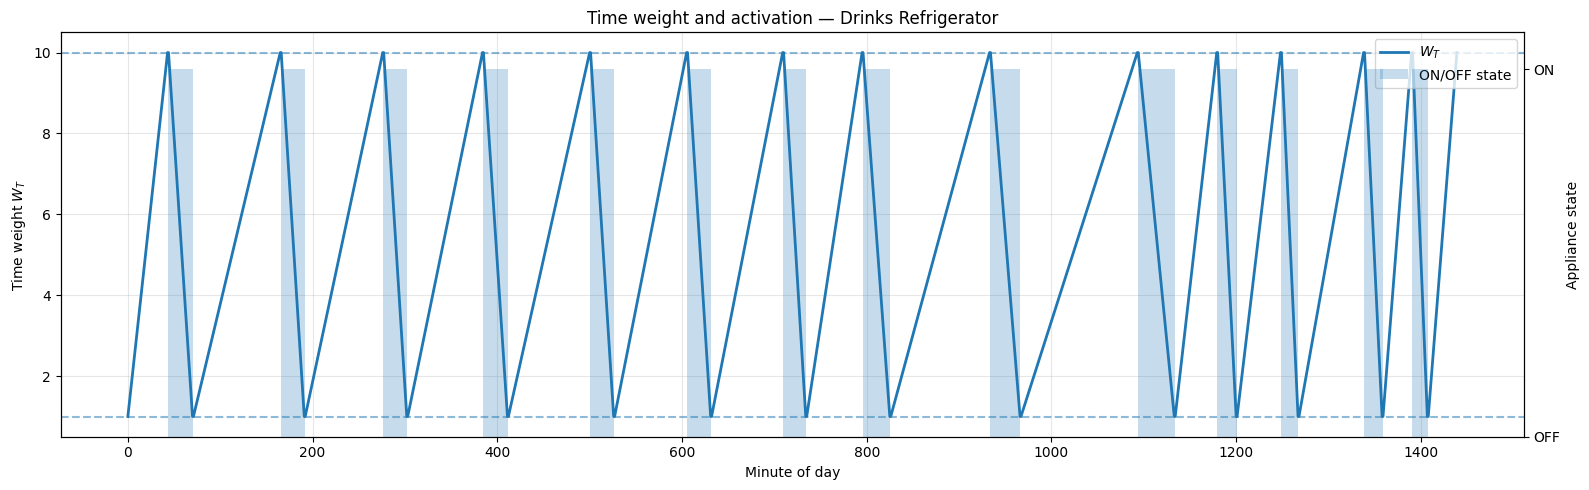

In [21]:
plot_device_weight_and_activation(
    device="Drinks Refrigerator",
    W_matrix=WT_FC_matrix,
    X_matrix=X_onoff_FC_matrix,
    dev_names=dev_names,
    Type=Type
)
plot_device_weight_and_activation(
    device="Drinks Refrigerator",
    W_matrix=WT_transition_matrix,
    X_matrix=X_onoff_FC_matrix,
    dev_names=dev_names,
    Type=Type
)

In [22]:
def compute_inside_boundary_percentage(
    W_matrix,
    Type,
    dev_names,
    tol=1e-6
):
    """
    Computes the percentage of valid samples for which:

        1 < WT < 10

    for every time-flexible appliance.
    """

    rows = []

    for j in np.where(Type == 2)[0]:

        W = np.asarray(W_matrix[:, j], dtype=float)

        # Remove possible NaN values
        W = W[~np.isnan(W)]

        if len(W) == 0:
            inside_percentage = np.nan
        else:
            at_min = np.isclose(W, 1.0, atol=tol)
            at_max = np.isclose(W, 10.0, atol=tol)

            inside = ~(at_min | at_max)

            inside_percentage = 100 * np.mean(inside)

        rows.append({
            "Device": dev_names[j],
            "Inside boundary [%]": inside_percentage
        })

    return pd.DataFrame(rows)

inside_original = compute_inside_boundary_percentage(
    W_matrix=WT_FC_matrix,
    Type=Type,
    dev_names=dev_names
)

inside_transition = compute_inside_boundary_percentage(
    W_matrix=WT_transition_matrix,
    Type=Type,
    dev_names=dev_names
)

In [23]:
inside_comparison = inside_original.merge(
    inside_transition,
    on="Device",
    suffixes=("_original", "_transition")
)

inside_comparison = inside_comparison.rename(columns={
    "Inside boundary [%]_original": "Original method [%]",
    "Inside boundary [%]_transition": "Transition-based method [%]"
})

inside_comparison["Improvement [p.p.]"] = (
    inside_comparison["Transition-based method [%]"]
    - inside_comparison["Original method [%]"]
)

display(inside_comparison)

,Device,Original method [%],Transition-based method [%],Improvement [p.p.]
0,Drinks Refrigerator,97.847222,95.972222,-1.875000
1,Blast Chiller,57.569444,97.083333,39.513889
2,Garde Manger,86.666667,86.527778,-0.138889
3,Ice Machine,22.708333,79.375000,56.666667
4,Dual Fryer,77.291667,79.375000,2.083333
5,Salamander,79.652778,99.583333,19.930556
6,Infrared Shelf,72.986111,98.750000,25.763889


In [24]:
def plot_inside_boundary_comparison(
    W_original,
    W_transition,
    Type,
    dev_names,
    tol=1e-6,
    figsize=(14, 6)
):
    """
    Compares the percentage of time spent inside the open weight
    interval 1 < WT < 10 for two characterization methods.
    """

    original = compute_inside_boundary_percentage(
        W_original,
        Type,
        dev_names,
        tol
    )

    transition = compute_inside_boundary_percentage(
        W_transition,
        Type,
        dev_names,
        tol
    )

    comparison = original.merge(
        transition,
        on="Device",
        suffixes=("_original", "_transition")
    )

    comparison = comparison.rename(columns={
        "Inside boundary [%]_original": "Original method",
        "Inside boundary [%]_transition": "Transition-based method"
    })

    devices = comparison["Device"].values
    original_values = comparison["Original method"].values
    transition_values = comparison["Transition-based method"].values

    x = np.arange(len(devices))
    width = 0.38

    fig, ax = plt.subplots(figsize=figsize)

    bars_original = ax.bar(
        x - width / 2,
        original_values,
        width,
        label="Original method"
    )

    bars_transition = ax.bar(
        x + width / 2,
        transition_values,
        width,
        label="Transition-based method"
    )

    ax.set_ylabel(r"Time within $1 < W_T < 10$ [%]")
    ax.set_xlabel("Appliance")
    ax.set_title(
        "Comparison of time-weight characterization methods"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        devices,
        rotation=35,
        ha="right"
    )

    ax.set_ylim(0, 105)
    ax.grid(
        axis="y",
        alpha=0.3
    )

    ax.legend()

    # Add values above the bars
    ax.bar_label(
        bars_original,
        fmt="%.1f",
        padding=3,
        fontsize=9
    )

    ax.bar_label(
        bars_transition,
        fmt="%.1f",
        padding=3,
        fontsize=9
    )

    plt.tight_layout()
    plt.show()

    return comparison

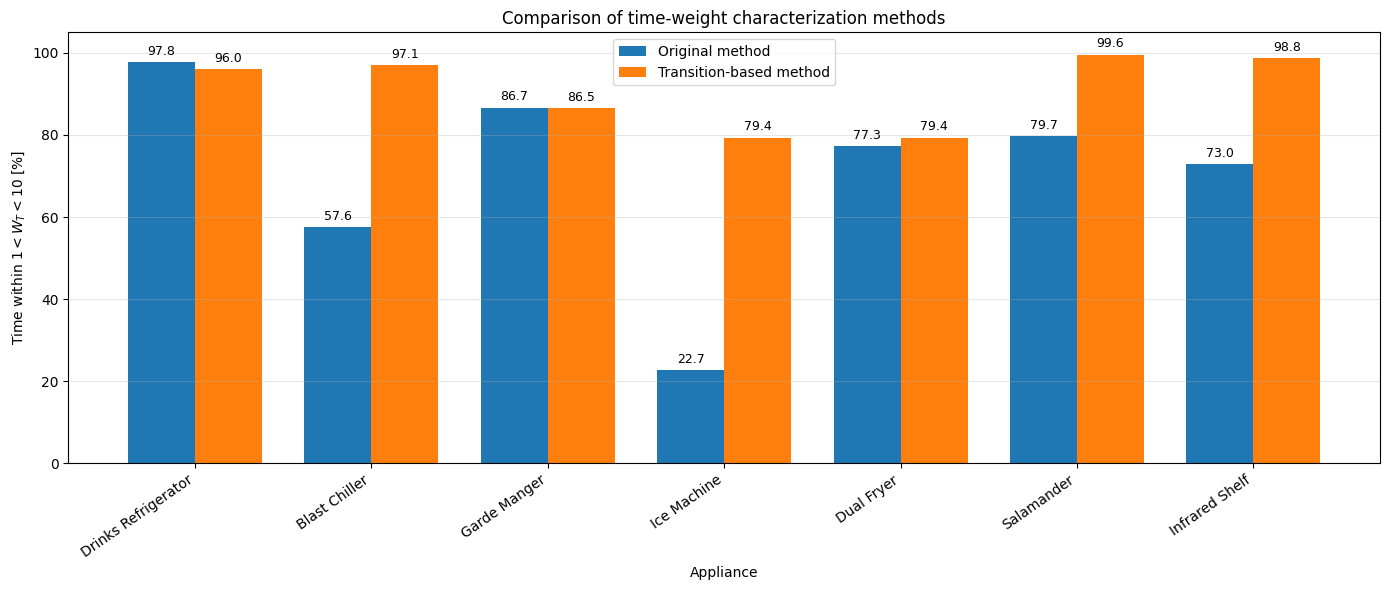

In [25]:
inside_comparison = plot_inside_boundary_comparison(
    W_original=WT_FC_matrix,
    W_transition=WT_transition_matrix,
    Type=Type,
    dev_names=dev_names
)

In [26]:
def extract_state_episodes(X):
    """
    Extracts consecutive ON/OFF episodes from a binary trajectory.

    Returns
    -------
    episodes : pandas.DataFrame
        Columns:
            state
            start_minute
            end_minute
            length_min
    """

    X = np.asarray(X, dtype=int)

    if len(X) == 0:
        return pd.DataFrame(
            columns=[
                "state",
                "start_minute",
                "end_minute",
                "length_min"
            ]
        )

    episodes = []
    start = 0
    current_state = X[0]

    for t in range(1, len(X)):

        if X[t] != current_state:

            episodes.append({
                "state": int(current_state),
                "start_minute": int(start),
                "end_minute": int(t - 1),
                "length_min": int(t - start)
            })

            start = t
            current_state = X[t]

    # Final episode
    episodes.append({
        "state": int(current_state),
        "start_minute": int(start),
        "end_minute": int(len(X) - 1),
        "length_min": int(len(X) - start)
    })

    return pd.DataFrame(episodes)

def characterize_episode_lengths_by_timezone(
    X,
    aggregation="median"
):
    """
    Computes representative ON and OFF episode lengths for each timezone.

    Parameters
    ----------
    X : array-like
        Minute-level binary state.

    aggregation : str
        'median' or 'mean'.

    Returns
    -------
    T_ON_ref : ndarray, shape (4,)
        Representative ON duration per timezone.

    T_OFF_ref : ndarray, shape (4,)
        Representative OFF duration per timezone.

    episodes : pandas.DataFrame
        Extracted episodes with timezone assignment.
    """

    episodes = extract_state_episodes(X)

    episodes["timezone"] = episodes["start_minute"].apply(
        get_time_zone
    )

    if aggregation == "median":
        aggregation_function = np.median

    elif aggregation == "mean":
        aggregation_function = np.mean

    else:
        raise ValueError(
            "aggregation must be 'median' or 'mean'."
        )

    T_ON_ref = np.full(4, np.nan)
    T_OFF_ref = np.full(4, np.nan)

    for tz in range(4):

        on_lengths = episodes.loc[
            (episodes["timezone"] == tz) &
            (episodes["state"] == 1),
            "length_min"
        ].to_numpy()

        off_lengths = episodes.loc[
            (episodes["timezone"] == tz) &
            (episodes["state"] == 0),
            "length_min"
        ].to_numpy()

        if len(on_lengths) > 0:
            T_ON_ref[tz] = aggregation_function(on_lengths)

        if len(off_lengths) > 0:
            T_OFF_ref[tz] = aggregation_function(off_lengths)

    return T_ON_ref, T_OFF_ref, episodes


In [28]:
T_ON_ref, T_OFF_ref, episodes = (
    characterize_episode_lengths_by_timezone(
        X_onoff_FC_matrix[:, j],
        aggregation="median"
    )
)
print(f"Representative ON durations by timezone: {T_ON_ref}")
print(f"Representative OFF durations by timezone: {T_OFF_ref}")

Representative ON durations by timezone: [nan 33. nan nan]
Representative OFF durations by timezone: [888.   1.  nan  71.]
